---
title: "Evaluate a model"
subtitle: "Fit CCA with evaluate_models, read what it returns, and check it"
description: "Run PyCPT's evaluate_models on CFSv2 and local CHIRPS v3.0 for OND 2023, separate cross-validated from in-sample results, compare with the Fit & diagnose case, and use PyCPT's plots."
execute:
  enabled: false
---

`evaluate_models` is the step that calls CPT. It fits the calibration, produces
cross-validated hindcasts, a forecast for 2023 and skill maps, and writes them to
the case folder. This chapter runs it on the inputs from chapters 2 and 3, then
looks closely at **what each returned number is**, because the returned objects
mix results of different kinds.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, and the case folder from chapters
1 to 3. No data is downloaded: PyCPT reuses the files already in the folder.
:::

## 1. Load the inputs

The settings are the ones from chapter 1. The predictor files come from chapter 2
and the predictand is the local CHIRPS v3.0 file built in chapter 3.

In [1]:
from pathlib import Path
import datetime as dt
import inspect
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Image, display
import pycpt
from pycpt import notebook as pycpt_notebook

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
sys.path.insert(0, str(repo))
from pycpt_tutorial import figures
figures.use_style()

MOS = "CCA"
predictor_names = ["CFSv2.PRCP"]
predictand_name = "CHIRPS3.PRCP"
download_args = {
    "fdate": dt.datetime(2023, 9, 1),
    "target": "Oct-Dec",
    "target_first_year": 1991,
    "target_final_year": 2020,
    "predictor_extent": {"west": 85, "east": 155, "south": -20, "north": 20},
    "predictand_extent": {"west": 94, "east": 142, "south": -12, "north": 7},
}
cpt_args = {
    "transform_predictand": None,
    "tailoring": None,
    "cca_modes": (2, 2),
    "x_eof_modes": (3, 3),
    "y_eof_modes": (3, 3),
    "validation": "crossvalidation",
    "drymask_threshold": None,
    "skillmask_threshold": None,
    "crossvalidation_window": 5,
    "synchronous_predictors": True,
}
force_download = False

case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = pycpt.setup(case_dir, download_args["predictor_extent"])
local_predictand_file = domain_dir / "data" / "local-CHIRPS3-OND-1991-2020.nc"
Y, hindcast_data, forecast_data = pycpt.download_data(
    predictand_name, local_predictand_file, predictor_names,
    download_args, domain_dir, force_download)

Input data will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



The predictand is named `CHIRPS3.PRCP` here, not `CHIRPS3 (local)` as in chapter 3.
For a local file the name is only a label, but step 7 shows that one plotting
function reads it.

## 2. What `evaluate_models` does

Before running it, read it. For CCA, the installed PyCPT 2.10.4 source does the
following for each model:

In [2]:
source = inspect.getsource(pycpt_notebook.evaluate_models).splitlines()
start = next(i for i, line in enumerate(source) if "if str(MOS).upper() == 'CCA'" in line)
end = next(i for i, line in enumerate(source) if "elif str(MOS).upper() == 'PCR'" in line)
for number in range(start, end):
    if source[number].strip():
        print(f"{number + 1:4d} | {source[number]}")

  24 |         if str(MOS).upper() == 'CCA':
  26 |             # fit CCA model between X & Y and produce real-time forecasts for F
  27 |             cca_h, cca_rtf, cca_s, cca_px, cca_py = cc.canonical_correlation_analysis(
  28 |                 model_hcst, Y, F=forecast_data[i], **cpt_args
  29 |             )
  31 |             # fit CCA model again between X & Y, and produce in-sample probabilistic hindcasts
  32 |             # this is using X in place of F, with the year coordinates changed to n+100 years
  33 |             # because CPT does not allow you to make forecasts for in-sample data
  34 |             cca_h, cca_f, cca_s, cca_px, cca_py = cc.canonical_correlation_analysis(
  35 |                 model_hcst, Y, \
  36 |                 F=ce.redate(model_hcst, yeardelta=48), **cpt_args
  37 |             )
  38 |             cca_h = xr.merge([cca_h, ce.redate(cca_f.probabilistic, yeardelta=-48), ce.redate(cca_f.prediction_error_variance, yeardelta=-48)])
  40 |         

Read it as three steps:

1. **First fit.** CCA on X and Y with `F` set to the real 2023 forecast input. Only
   the forecast from this call (`cca_rtf`) is kept.
2. **Second fit.** The same CCA again, but `F` is the training predictor X itself,
   shifted forward by 48 years with `cptextras.redate` so CPT will accept it as
   "future" input. (The comment above the call says 100 years; the code passes
   `yeardelta=48`.) The probabilities and prediction-error variance from this call
   are shifted back and merged into the hindcasts. They are probabilities for
   years the model was trained on.
3. **Probabilistic scores** are computed from those in-sample probabilities. The
   source's own comment says this "produces unrealistically optimistic values".

The second call also replaces the first call's hindcasts, skill and patterns. Its
cross-validation uses the same X, Y and settings as the first.

## 3. Run it

In [3]:
start = time.monotonic()
hcsts, fcsts, skill, pxs, pys = pycpt.evaluate_models(
    hindcast_data, MOS, Y, forecast_data, cpt_args, domain_dir, predictor_names)
print(f"evaluate_models finished in {time.monotonic() - start:.0f} s")

evaluate_models finished in 38 s


## 4. What came back

Five lists, one entry per model. With one model, each list has one item.

In [4]:
rows = []
for name, ds in [("hcsts", hcsts[0]), ("fcsts", fcsts[0]), ("skill", skill[0]),
                 ("pxs", pxs[0]), ("pys", pys[0])]:
    for variable, a in ds.data_vars.items():
        rows.append({"returned": name, "variable": variable,
                     "dimensions": ", ".join(f"{d}={n}" for d, n in a.sizes.items()),
                     "units attribute": a.attrs.get("units", "")})
pd.DataFrame(rows)

,returned,variable,dimensions,units attribute
0,hcsts,deterministic,"T=30, Y=76, X=192",mm
1,hcsts,probabilistic,"C=3, T=30, Y=76, X=192",probability (%)
2,hcsts,prediction_error_variance,"T=30, Y=76, X=192",mm (squared)
3,fcsts,deterministic,"T=1, Y=76, X=192",mm
4,fcsts,probabilistic,"C=3, T=1, Y=76, X=192",probability (%)
5,fcsts,prediction_error_variance,"T=1, Y=76, X=192",mm (squared)
6,skill,pearson,"Y=76, X=192",
7,skill,spearman,"Y=76, X=192",
8,skill,two_alternative_forced_choice,"Y=76, X=192",
9,skill,roc_area_below_normal,"Y=76, X=192",


In [5]:
print("Files written to output/:")
for f in sorted((domain_dir / "output").iterdir()):
    print(f"  {f.name}  ({f.stat().st_size / 1000:.0f} kB)")

Files written to output/:
  CFSv2.PRCP_cca_x_spatial_loadings.nc  (1437 kB)
  CFSv2.PRCP_cca_y_spatial_loadings.nc  (7046 kB)
  CFSv2.PRCP_crossvalidated_cca_hindcasts.nc  (17535 kB)
  CFSv2.PRCP_realtime_cca_forecasts.nc  (607 kB)
  CFSv2.PRCP_skillscores_cca.nc  (1068 kB)


## 5. Which numbers are which

The step 2 source decides how each result may be used. The table summarises it.

| Result | Where it comes from | Use it as |
| --- | --- | --- |
| `hcsts.deterministic` | cross-validated hindcasts, window of 5 | an out-of-sample check of the deterministic forecast, within the training period |
| `hcsts.probabilistic`, `hcsts.prediction_error_variance` | second fit, X re-dated as forecast input | **in-sample**: not evidence of probability skill |
| `fcsts` (all three variables) | first fit, the real September 2023 input | the 2023 forecast |
| `skill`: `pearson`, `spearman`, `two_alternative_forced_choice`, `roc_area_below_normal`, `roc_area_above_normal`, `root_mean_squared_error` | CPT's deterministic scores; the next cell checks that they score the cross-validated hindcasts | deterministic skill, the six metrics the template plots |
| `skill`: `generalized_roc`, `ignorance`, `rank_probability_skill_score` | `probabilistic_forecast_verification` on the in-sample probabilities | **optimistic**: the template labels `generalized_roc` and `rank_probability_skill_score` "in sample"; `ignorance` comes from the same call |
| `pxs`, `pys` | patterns from the full training period | diagnostics, not skill |

The template plots the six deterministic metrics. Chapter 5 returns to the
probabilities.

The claim that the deterministic scores describe the cross-validated hindcasts can
be checked directly: recompute the Pearson correlation and the RMSE between
`hcsts.deterministic` and the observations at every cell, and compare them with
CPT's maps.

In [6]:
cv = hcsts[0].deterministic.transpose("T", "Y", "X")
obs = Y.transpose("T", "Y", "X")
anom_cv, anom_obs = cv - cv.mean("T"), obs - obs.mean("T")
pearson_check = (anom_cv * anom_obs).sum("T") / np.sqrt((anom_cv ** 2).sum("T") * (anom_obs ** 2).sum("T"))
rmse_check = np.sqrt(((cv - obs) ** 2).mean("T"))

for label, mine, cpt in [("pearson", pearson_check, skill[0].pearson),
                         ("root_mean_squared_error", rmse_check, skill[0].root_mean_squared_error)]:
    gap = np.abs(mine.values - cpt.transpose("Y", "X").values)
    print(f"{label}: largest difference from CPT's map {np.nanmax(gap):.4f} "
          f"over {int(np.isfinite(gap).sum())} cells")

pearson: largest difference from CPT's map 0.0000 over 3240 cells
root_mean_squared_error: largest difference from CPT's map 0.0013 over 3240 cells


## 6. Compare with the Fit & diagnose case

The [Fit & diagnose](../chapters/fit-diagnose-2023.qmd) case ran the same CCA
settings through `cptcore` directly. Chapter 3 showed the predictand is identical.
Chapter 2 showed the predictor is not: PyCPT's CFSv2 totals weight the three months
equally, while the case weighted them by days, with differences up to 8.25 mm.
The table measures how much that changes the results, over the 3,240 predictand cells.

In [7]:
controls = repo / "docs/data/fitting-2023/controls"
control_forecast = xr.open_dataset(controls / "OND-cca-forecasts.nc")
control_hindcast = xr.open_dataset(controls / "OND-cca-hindcasts.nc")
control_skill = xr.open_dataset(controls / "OND-cca-native_skill.nc")
cells = Y.notnull().all("T")


def compare(label, ours, theirs):
    ours = ours.reindex(X=theirs["X"], Y=theirs["Y"], method="nearest", tolerance=1e-3).where(cells)
    a = ours.transpose(*theirs.dims).values
    b = theirs.values
    gap = np.abs(a - b)
    return {"result": label, "units": theirs.attrs.get("units", ""),
            "largest difference": float(np.nanmax(gap)),
            "mean difference": float(np.nanmean(gap)),
            "median of the case's values": float(np.nanmedian(np.abs(b)))}


rows = [compare(f"2023 forecast: {v}", fcsts[0][v], control_forecast[v]) for v in control_forecast.data_vars]
rows.append(compare("CV hindcasts: deterministic", hcsts[0].deterministic, control_hindcast.deterministic))
rows += [compare(f"skill: {v}", skill[0][v], control_skill[v]) for v in control_skill.data_vars]
pd.DataFrame(rows).set_index("result").round(4)

,units,largest difference,mean difference,median of the case's values
result,,,,
2023 forecast: deterministic,mm,0.0235,0.0066,617.5582
2023 forecast: probabilistic,probability (%),0.0410,0.0057,24.1579
2023 forecast: prediction_error_variance,mm (squared),539.3447,29.2053,30431.3300
CV hindcasts: deterministic,mm,2.5542,0.2239,783.1758
skill: pearson,,0.0019,0.0004,0.5883
skill: spearman,,0.0227,0.0011,0.5842
skill: two_alternative_forced_choice,,0.9195,0.0619,70.8046
skill: roc_area_below_normal,,0.0150,0.0005,0.8150
skill: roc_area_above_normal,,0.0106,0.0007,0.7350


The predictor difference measured in chapter 2 moves the results only slightly:
the 2023 deterministic forecast changes by hundredths of a millimetre, the
cross-validated hindcasts by up to a few millimetres, and the skill scores by small
fractions of their scales. The high-level `evaluate_models` path and the direct
`cptcore` path agree to the extent the inputs agree.

## 7. Plot the results

PyCPT has four plotting functions for these results: `plot_skill`,
`plot_eof_modes`, `plot_cca_modes` and `plot_forecasts`. Each saves PNG files in
the case's `figures/` folder. This chapter runs all four so those files exist, but
draws the figures on the page with the tutorial's figure helper from the same
returned data, in one consistent style. `figures.quiet_pycpt_plots()` stops PyCPT
from also drawing its versions inline; it does not change what PyCPT saves.

### Skill maps

`plot_skill` takes the list of metric names to draw. These are the template's six
deterministic metrics. The colour ranges below are the ones PyCPT uses for them.

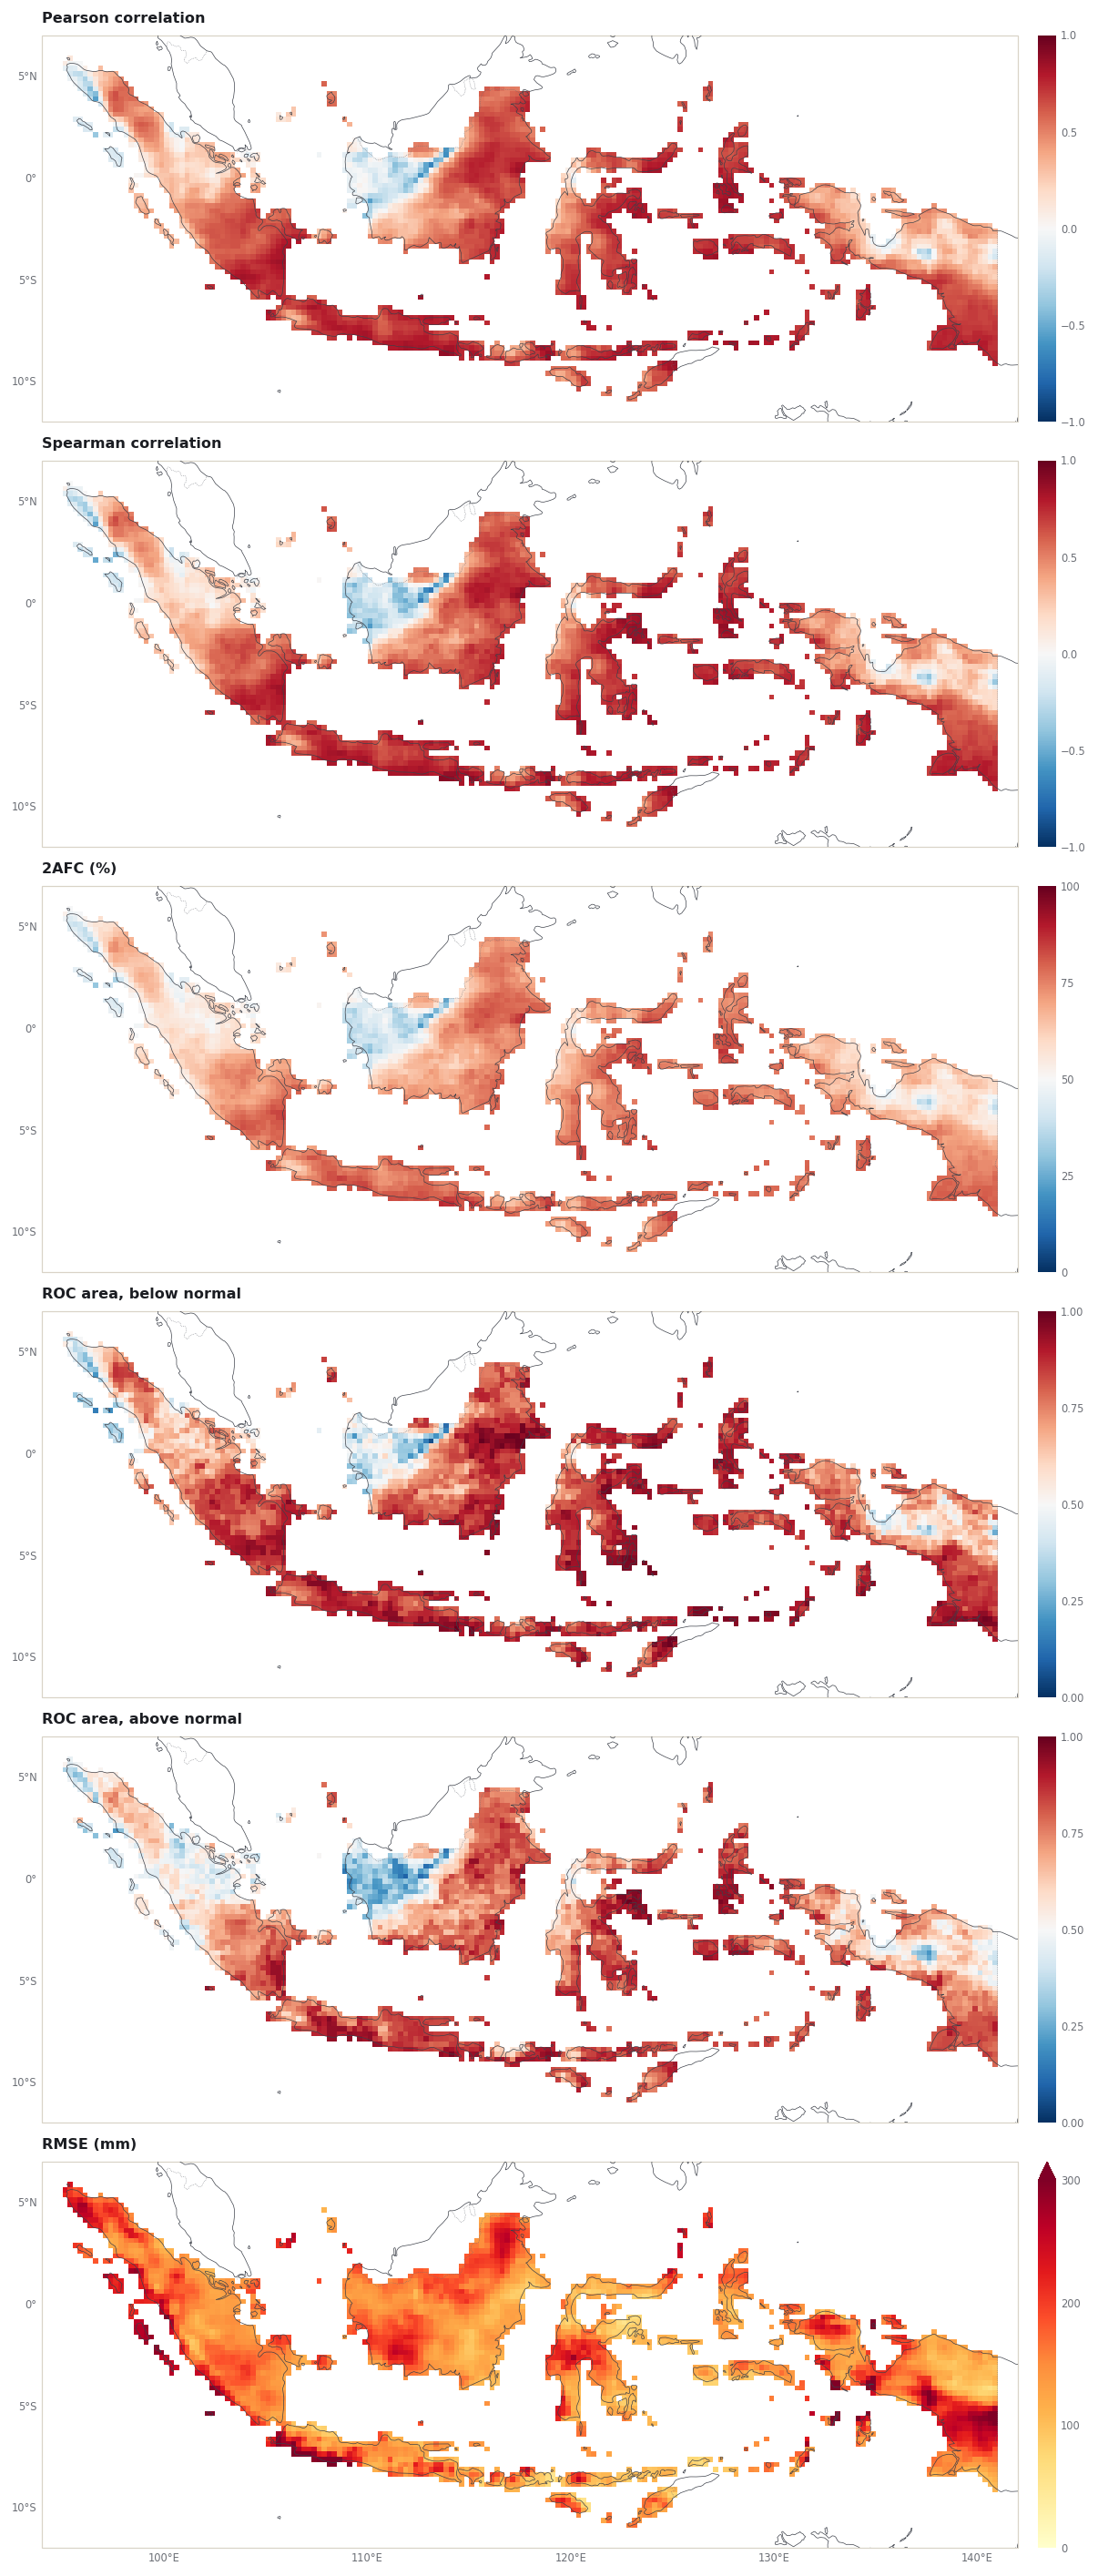

In [8]:
skill_metrics = ["pearson", "spearman", "two_alternative_forced_choice",
                 "roc_area_below_normal", "roc_area_above_normal", "root_mean_squared_error"]
with figures.quiet_pycpt_plots():
    pycpt.plot_skill(predictor_names, skill, MOS, domain_dir, skill_metrics)

predictor_box = figures.extent_of(download_args["predictor_extent"])
predictand_box = figures.extent_of(download_args["predictand_extent"])
figures.skill_figure(skill[0], predictand_box, skill_metrics)
plt.show()

### EOF and CCA patterns

The pattern plots draw a fixed number of modes: in PyCPT 2.10.4, `plot_eof_modes`
sets `nmodes = 5` and `plot_cca_modes` sets `nmodes = 3`. This case keeps 3 EOFs
and 2 CCA modes, so the cell below first checks which modes contain values.

In [9]:
x_patterns, y_patterns = pxs[0], pys[0]
for label, a in [("predictor EOF", x_patterns.x_eof_loadings), ("predictor CCA", x_patterns.x_cca_loadings),
                 ("predictand EOF", y_patterns.y_eof_loadings), ("predictand CCA", y_patterns.y_cca_loadings)]:
    filled = [int(m) for m in a["Mode"].values if int(a.sel(Mode=m).notnull().sum()) > 0]
    print(f"{label:>15} modes with values: {filled}")
print()
print("Predictor explained variance, modes 1-5 (%):",
      np.round(x_patterns.x_explained_variance.values[:5], 2).tolist())
print("Predictand explained variance, modes 1-5 (%):",
      np.round(y_patterns.y_explained_variance.values[:5], 2).tolist())

  predictor EOF modes with values: [1, 2, 3]
  predictor CCA modes with values: [1, 2]
 predictand EOF modes with values: [1, 2, 3]
 predictand CCA modes with values: [1, 2]

Predictor explained variance, modes 1-5 (%): [47.06, 17.62, 8.61, 4.74, 3.62]
Predictand explained variance, modes 1-5 (%): [51.33, 7.17, 5.85, 4.04, 3.61]


Only the retained modes have patterns; explained variance is reported for every
mode, retained or not. PyCPT's saved files therefore include empty ones: EOF modes
4 and 5, and CCA mode 3. The figures below draw the retained modes only: for each
mode, the predictor loadings, the predictand loadings and the two time series of
scores.

CFSV2.PRCP: EOF 1


CFSV2.PRCP: EOF 2


CFSV2.PRCP: EOF 3


CFSV2.PRCP: EOF 4


CFSV2.PRCP: EOF 5


CFSV2.PRCP: CCA MODE 1 - Canonical Correlation = 0.94


CFSV2.PRCP: CCA MODE 2 - Canonical Correlation = 0.46


CFSV2.PRCP: CCA MODE 3 - Canonical Correlation = nan


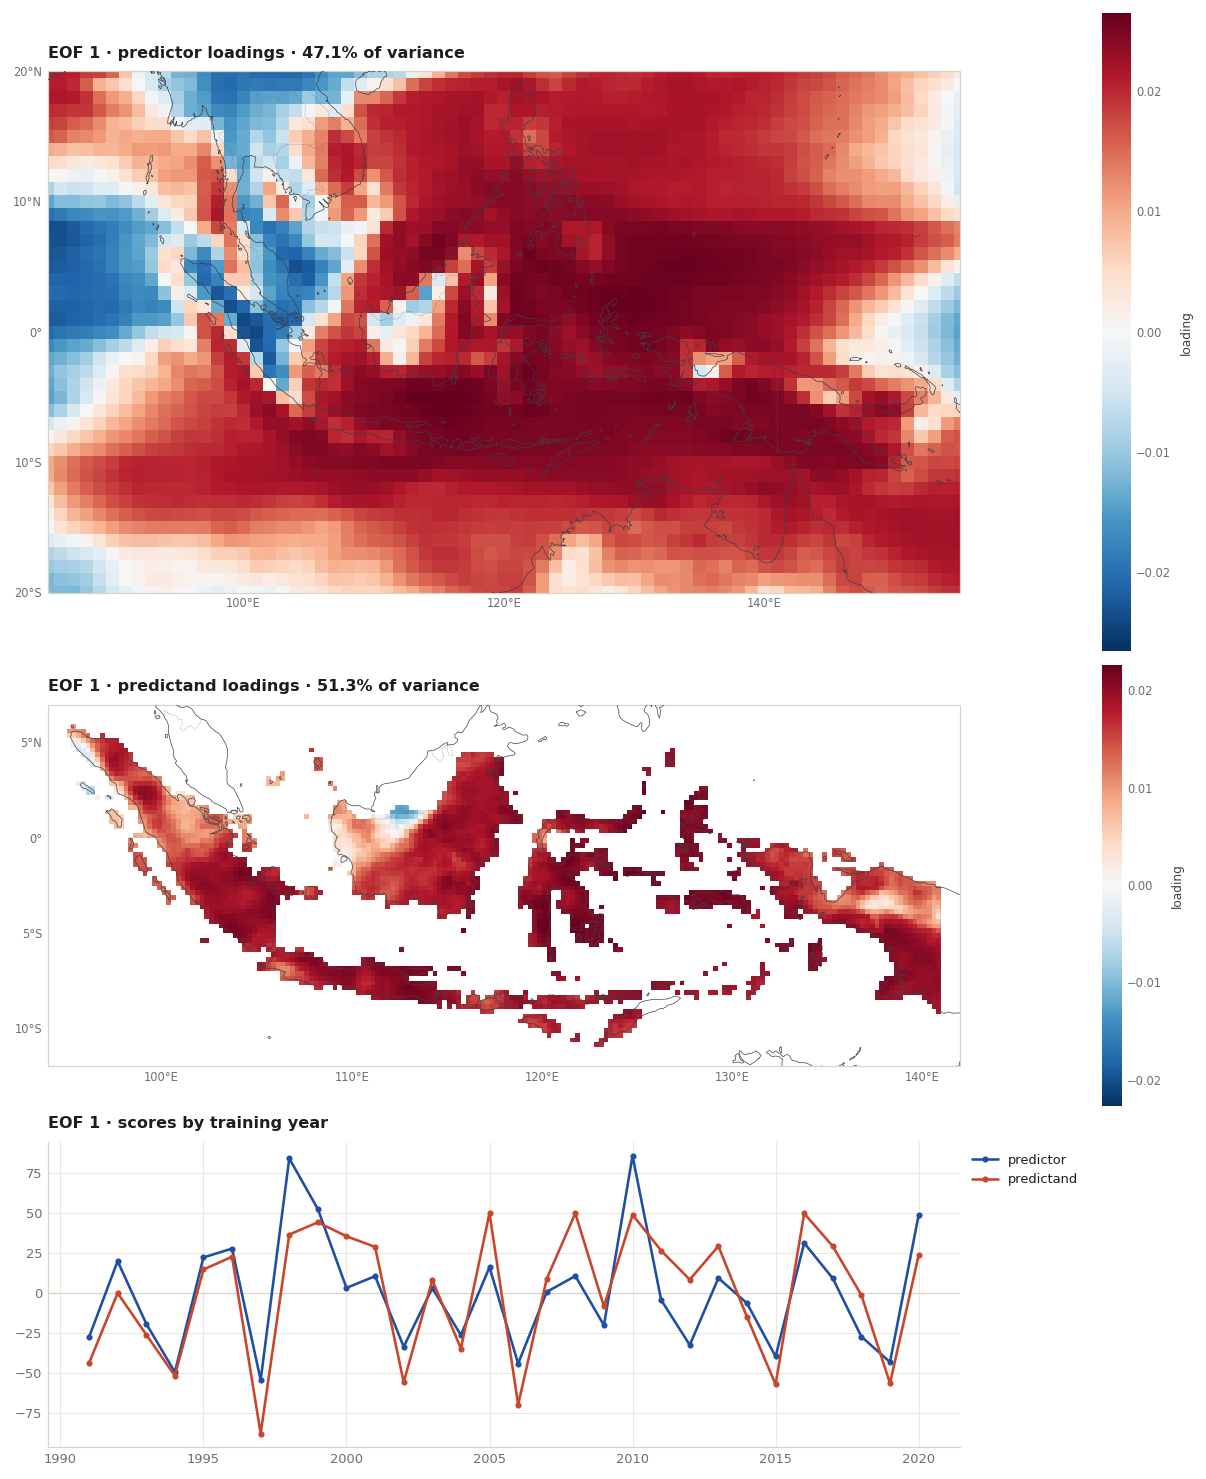

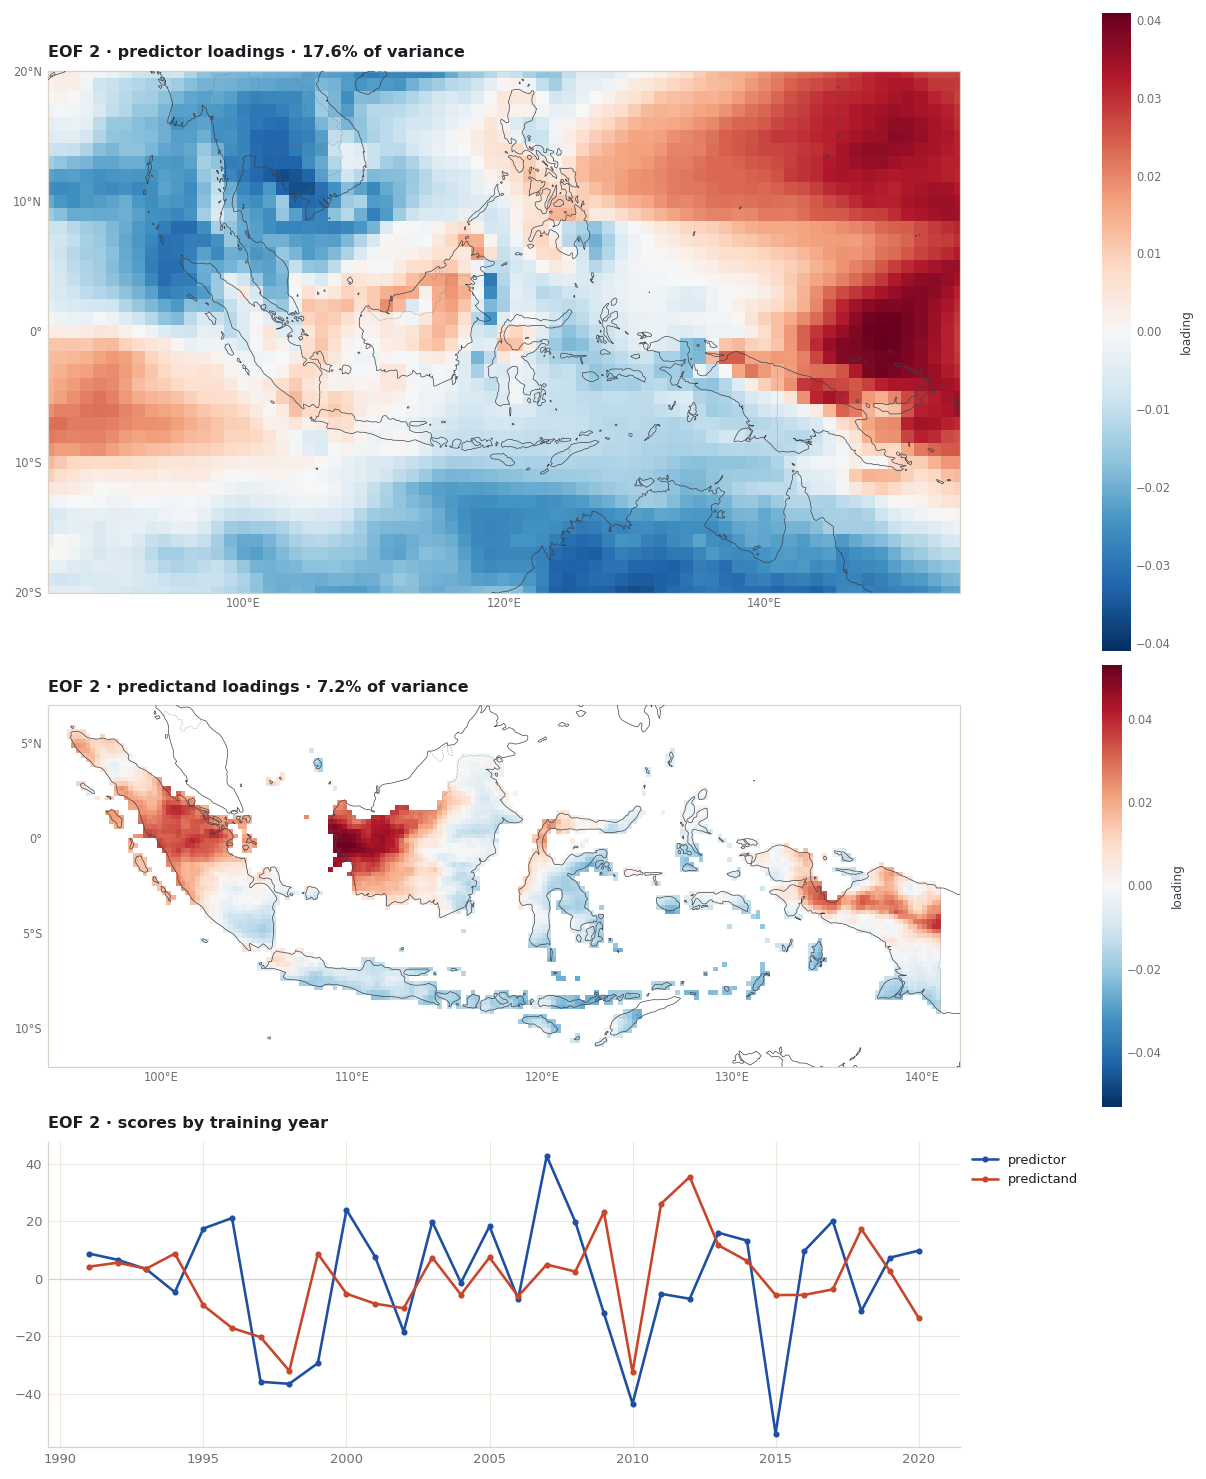

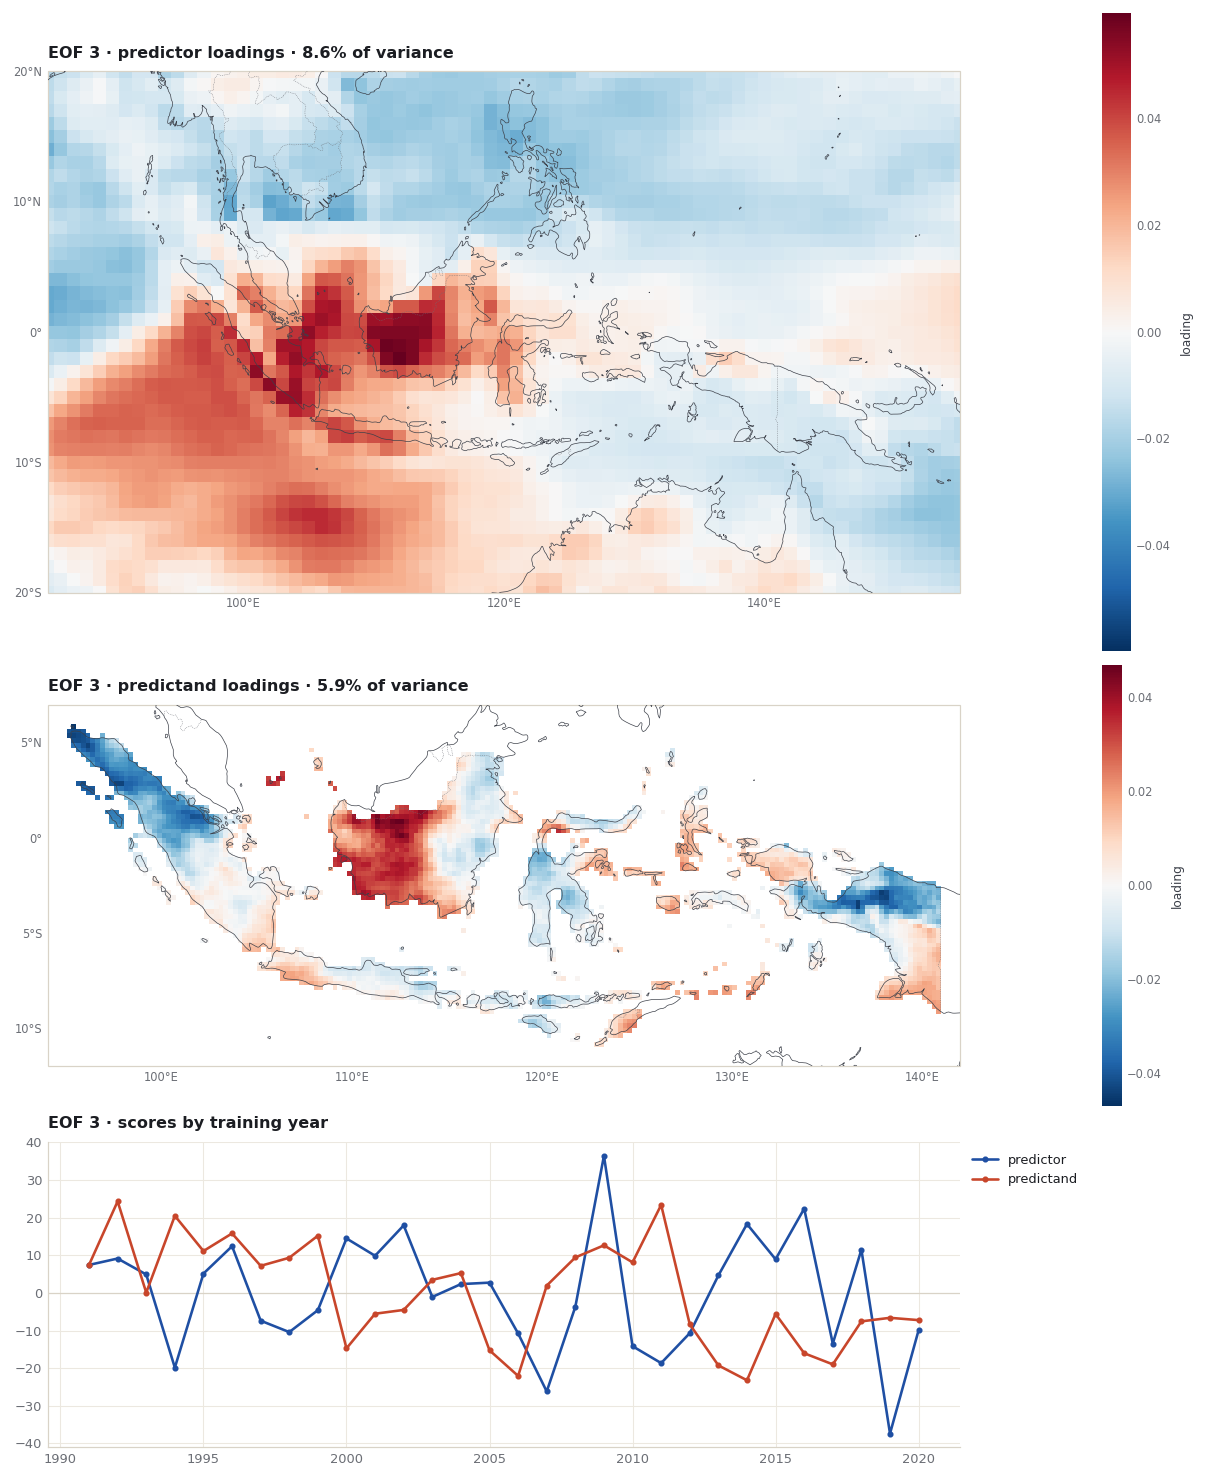

In [10]:
with figures.quiet_pycpt_plots():
    pycpt.plot_eof_modes(MOS, predictor_names, pxs, pys, domain_dir)
    pycpt.plot_cca_modes(MOS, predictor_names, pxs, pys, domain_dir)

for mode in [1, 2, 3]:
    figures.pattern_figure(x_patterns, y_patterns, "eof", mode, predictor_box, predictand_box)
    plt.show()

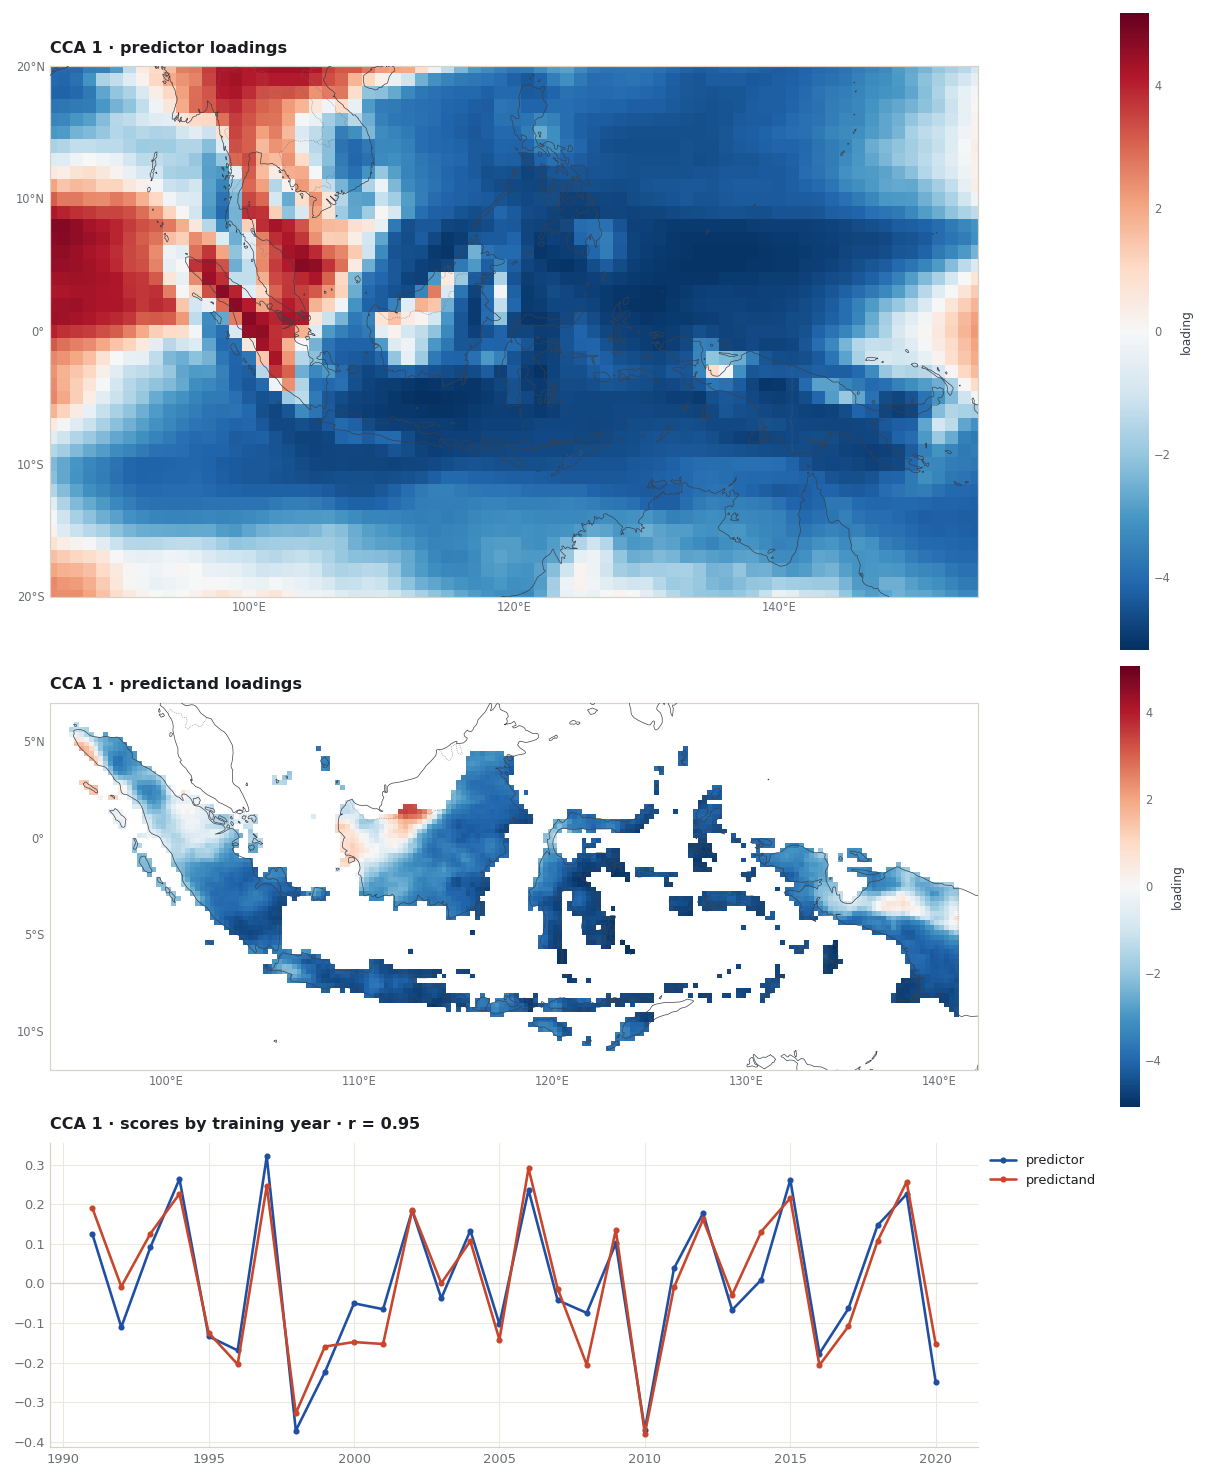

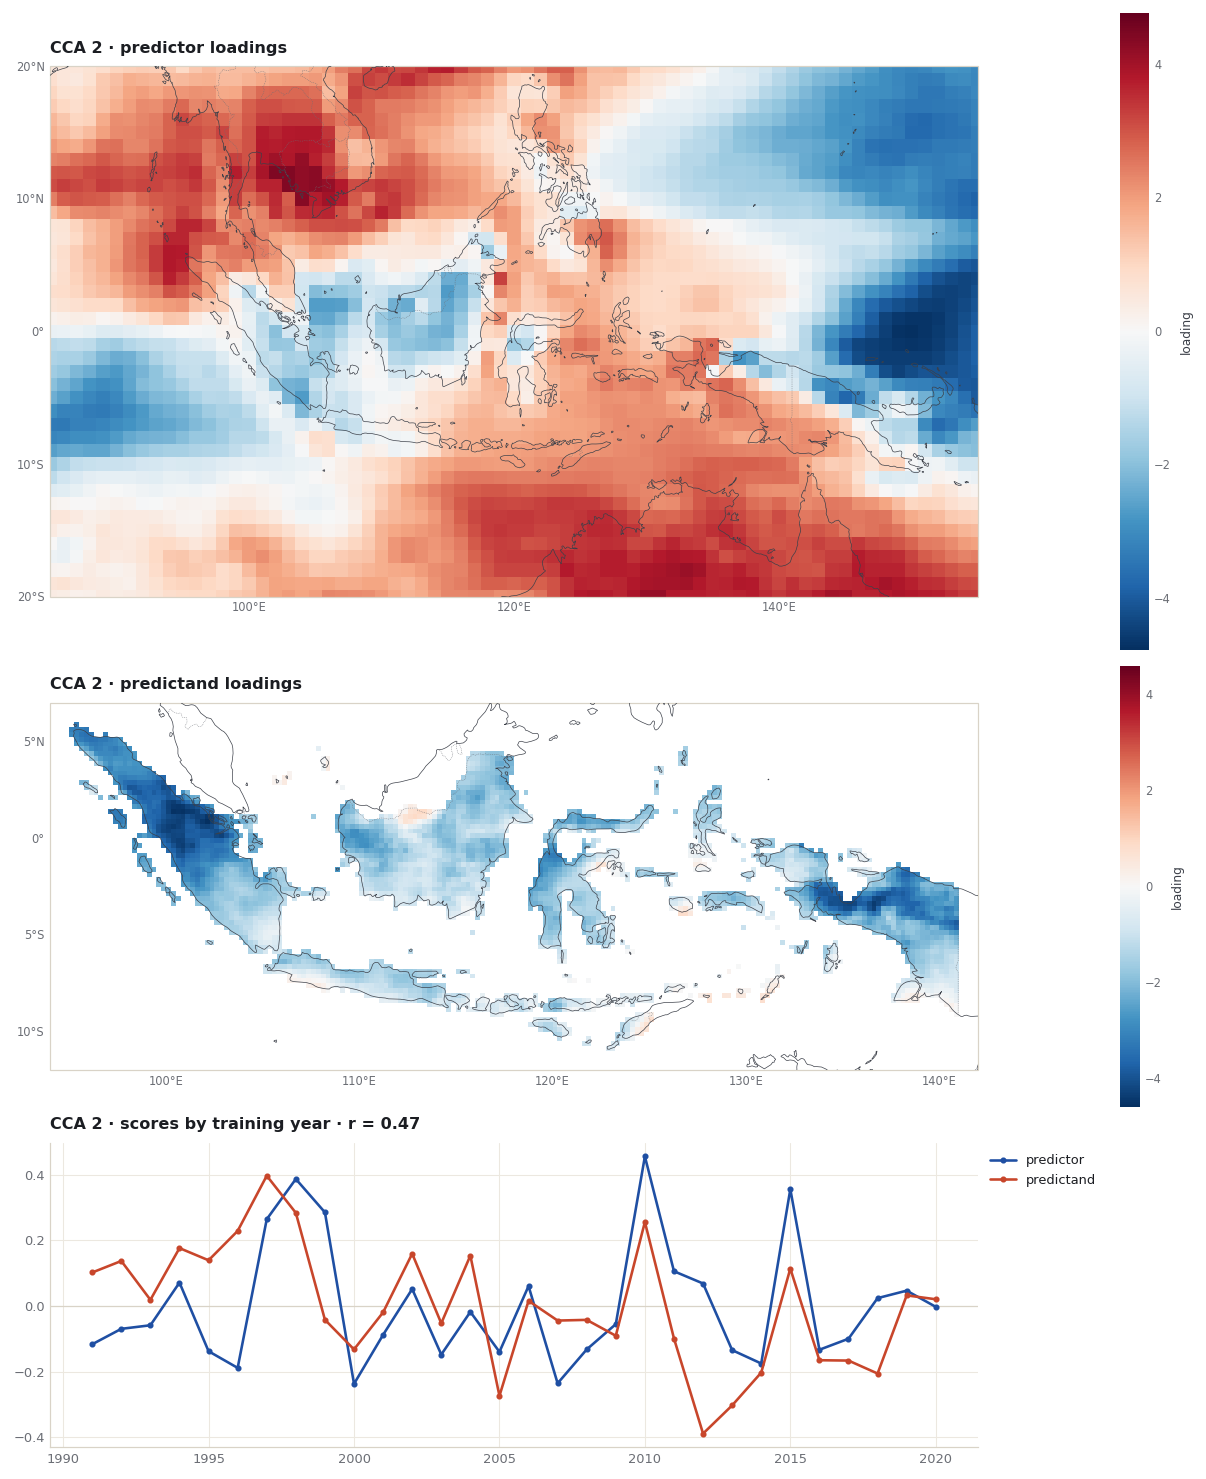

In [11]:
for mode in [1, 2]:
    figures.pattern_figure(x_patterns, y_patterns, "cca", mode, predictor_box, predictand_box)
    plt.show()

For CCA, the `r` in each title is the correlation between the predictor and
predictand score series, computed in the figure from the returned scores. The sign
of every mode is arbitrary: flipping both a pattern and its scores describes the
same mode.

These are patterns fitted on the full training period. They show what the
calibration uses; they are not evidence that the forecast is skilful.

### The forecast

`plot_forecasts` chooses its colour scale by searching the predictand name for
`PRCP` or a temperature code. In PyCPT 2.10.4, a name without one of them leaves
the scale undefined and the function stops with an `UnboundLocalError`; with
`CHIRPS3 (local)` as the name, it did. That is why this chapter uses `CHIRPS3.PRCP`.

Category coordinate C: ['1', '2', '3']


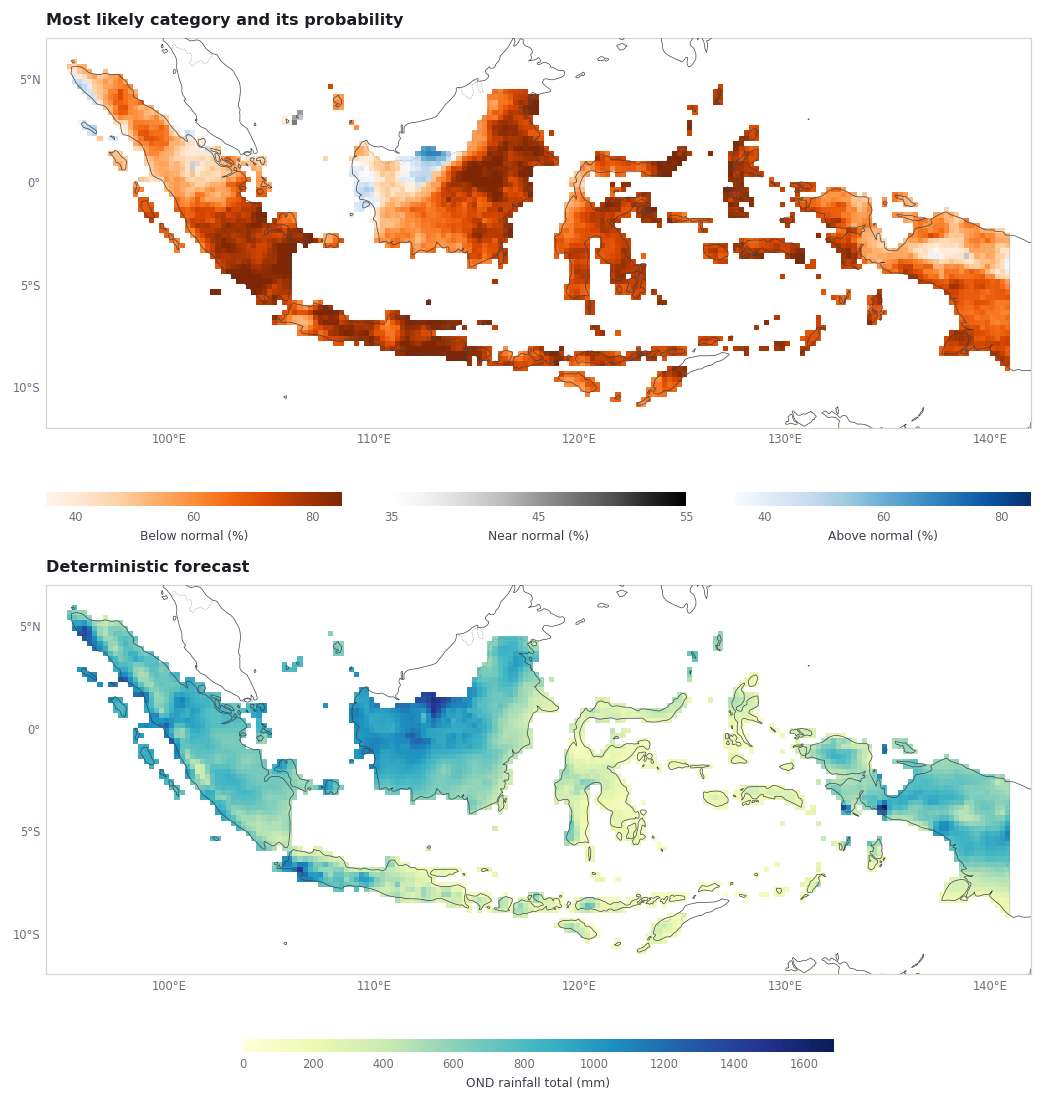

In [12]:
with figures.quiet_pycpt_plots():
    pycpt.plot_forecasts(cpt_args, predictand_name, fcsts, domain_dir, predictor_names, MOS)

print("Category coordinate C:", fcsts[0].probabilistic["C"].values.tolist())
figures.forecast_figure(fcsts[0], predictand_box)
plt.show()

The left map follows PyCPT's own rule for this view (`view_probabilistic` in
`cptextras`): each cell shows the category with the highest probability, coloured
by that probability. Category index 0 is below normal, 1 near normal and 2 above
normal, and the colour ranges, 35-85% for below and above normal and 35-55% for
near normal, are the ones PyCPT uses. The right map is the deterministic forecast
in mm. Chapter 5 explains how CPT defines the categories and what the
probabilities mean.

In [13]:
print("Figures written to figures/:")
for f in sorted((domain_dir / "figures").iterdir()):
    print(f"  {f.name}")

Figures written to figures/:
  CCA_CFSv2.PRCP_CCA_mode_1.png
  CCA_CFSv2.PRCP_CCA_mode_2.png
  CCA_CFSv2.PRCP_CCA_mode_3.png
  CCA_CFSv2.PRCP_EOF_mode_1.png
  CCA_CFSv2.PRCP_EOF_mode_2.png
  CCA_CFSv2.PRCP_EOF_mode_3.png
  CCA_CFSv2.PRCP_EOF_mode_4.png
  CCA_CFSv2.PRCP_EOF_mode_5.png
  CCA_CFSv2.PRCP_[determinstic-probabilistic]-Forecast.png
  CCA_models_skillMatrices.png
  Test.png


`Test.png` is a working file that `plot_forecasts` writes and leaves behind; it is
safe to ignore.

## What you have now

- A CCA fit through PyCPT's own `evaluate_models`, with its outputs in the case folder.
- A map of which returned numbers are cross-validated, which are in-sample and
  which are the 2023 forecast.
- A measured comparison with the Fit & diagnose case: same predictand, slightly
  different predictor, small differences in the results.
- PyCPT's four plot functions and the files they save, with two things to watch:
  empty files for modes that were not retained, and the predictand name.
- The same results drawn as skill maps, retained patterns and a forecast map.

The next chapter looks at the probabilistic forecast: tercile categories, CPT's
native probabilities and PyCPT's flexible forecasts.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
3. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
4. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/view.py`* (`view_probabilistic`) and `dlcolors.py` (`prepare_canvas`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/view.py>
5. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
6. IRI. *CPT-Core demonstration notebook* (`Demo/cptcore_demo.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Demo/cptcore_demo.ipynb>
7. CPT+. *430: Verification* (CPT help). <https://cptplus.org/Help/Tools_Verify.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
8. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
9. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
10. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
11. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
12. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>